# Kesit İstatistik — Kayıp, optimizasyon ve belirsizlik

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## Olabilirlik, çapraz entropi ve log kaybı

Aynı doğrulukta daha emin yanlış karar neden daha pahalı?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** İki olasılık tahmininin log kaybını ve Brier’ını karşılaştır.

**Yorum sınırı:** Kayıplar olasılık kalitesini ölçer; sıralama kalitesi veya eşik maliyetiyle aynı değildir.

**Alıştırma:** Yanlış kayda verilen .99 olasılığını .7 yap; doğruluk değişmeden kaybı izle.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


        model  log_kayip   Brier  dogruluk
0      Ilımlı   0.501734  0.1625      0.75
1  Aşırı emin   1.158830  0.2451      0.75


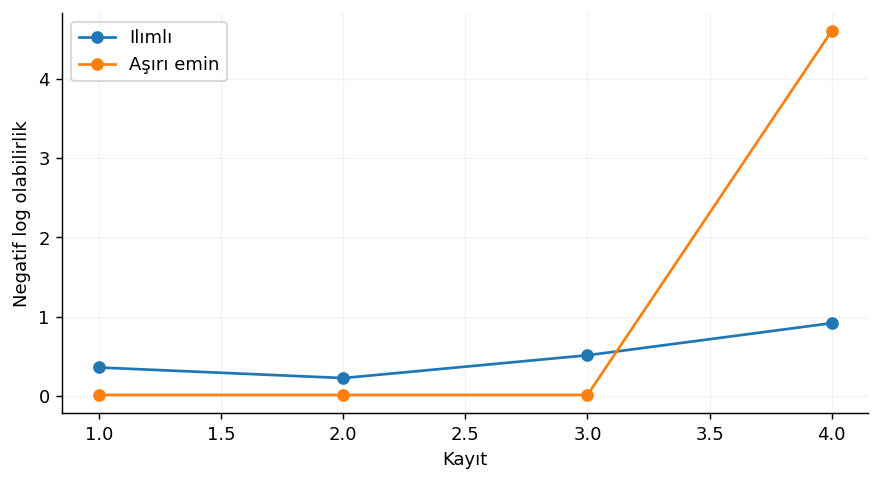

In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

y=np.array([1,0,1,0]);p1=np.array([.7,.2,.6,.6]);p2=np.array([.99,.01,.99,.99]);print(pd.DataFrame([{'model':name,'log_kayip':log_loss(y,p),'Brier':brier_score_loss(y,p),'dogruluk':np.mean((p>=.5)==y)} for name,p in [('Ilımlı',p1),('Aşırı emin',p2)]]))
plt.plot(range(1,5),-(y*np.log(p1)+(1-y)*np.log1p(-p1)),'o-',label='Ilımlı');plt.plot(range(1,5),-(y*np.log(p2)+(1-y)*np.log1p(-p2)),'o-',label='Aşırı emin');plt.xlabel('Kayıt');plt.ylabel('Negatif log olabilirlik');plt.legend()

## Gradyan inişi ve stokastik optimizasyon

Adım boyu optimizasyonu nasıl bozabilir?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Kayıp izlerini küçük, uygun ve büyük adım için karşılaştır.

**Yorum sınırı:** Konveks tek parametreli kare kayıp örneği; derin ağların tüm davranışını temsil etmez.

**Alıştırma:** Öğrenme hızına 1.1 ekle; taşma yerine ilk 20 adımda yükselen kaybı gözle.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'adim': 0.01, 'son_beta': np.float64(1.2949633208807263), 'son_kayip': np.float64(0.5762447424963499)}
{'adim': 0.1, 'son_beta': np.float64(2.0562781922604976), 'son_kayip': np.float64(0.08421888194582039)}
{'adim': 0.8, 'son_beta': np.float64(2.0563216685858157), 'son_kayip': np.float64(0.08421887972373926)}


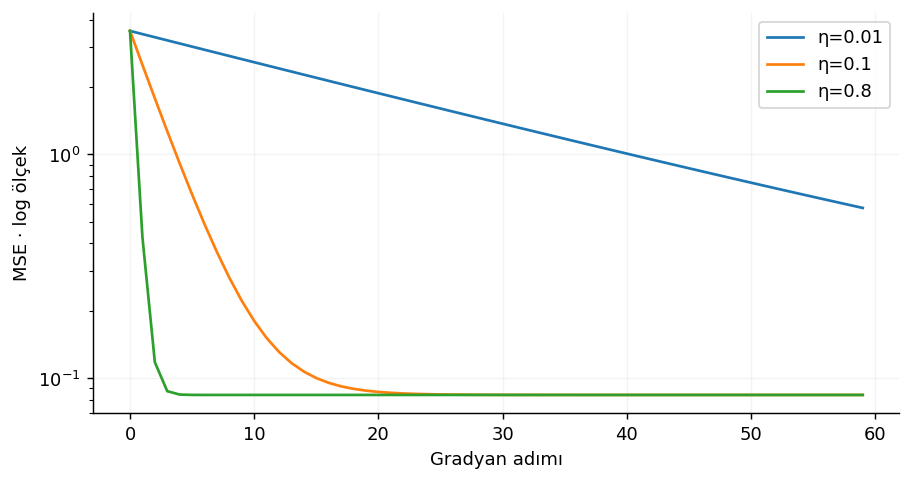

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=rng.normal(size=100);y=2*x+rng.normal(0,.3,100)
for rate in [.01,.1,.8]:
 b=0.;history=[]
 for step in range(60):
  pred=b*x;history.append(np.mean((pred-y)**2));grad=2*np.mean(x*(pred-y));b-=rate*grad
 print({'adim':rate,'son_beta':b,'son_kayip':history[-1]});plt.semilogy(history,label=f'η={rate}')
plt.xlabel('Gradyan adımı');plt.ylabel('MSE · log ölçek');plt.legend()

## Vektörler, kovaryans matrisi ve gradyan

Gradyanı sayısal farkla doğrulayabilir miyim?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Analitik ve sonlu fark gradyanlarının eşleşmesini denetle.

**Yorum sınırı:** Kovaryans özdeğerleri ölçekteki değişime duyarlıdır; merkezleme ve n−1 tanımı korunur.

**Alıştırma:** İkinci sütunu 100 ile çarp; kovaryans ve gradyan ölçeğinin etkisini yaz.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'gradyan': [-0.9049179600196501, 0.13106047921004177], 'sonlu_fark': [-0.9049179600095769, 0.13106047919153596], 'kovaryans': [[0.7933380973651366, 0.4788164998753933], [0.4788164998753933, 0.5323672287029223]]}


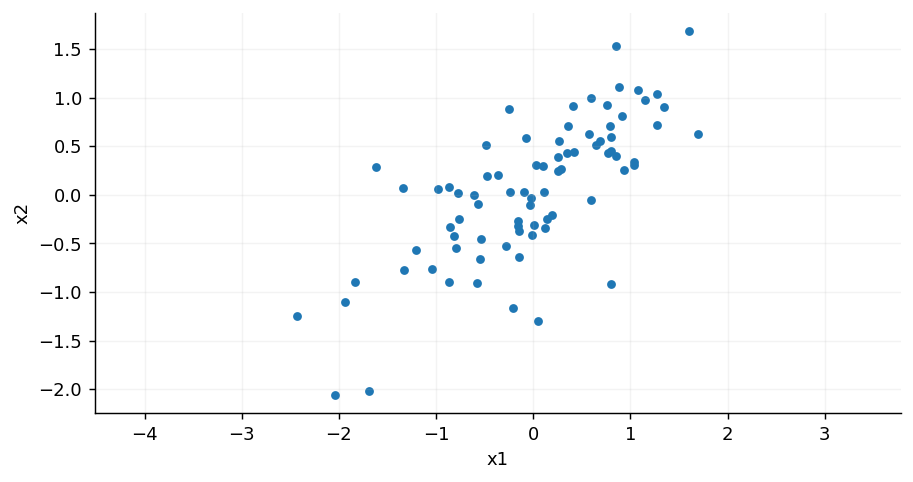

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

X=rng.normal(size=(80,2));X[:,1]=.7*X[:,0]+.5*X[:,1];y=X@np.array([2.,-1.])+rng.normal(0,.3,80);b=np.array([.5,.5]);loss=lambda v:np.mean((X@v-y)**2);g=2*X.T@(X@b-y)/len(y);eps=1e-6;numeric=np.array([(loss(b+eps*np.eye(2)[j])-loss(b-eps*np.eye(2)[j]))/(2*eps) for j in range(2)])
print({'gradyan':g.tolist(),'sonlu_fark':numeric.tolist(),'kovaryans':np.cov(X,rowvar=False).tolist()});assert np.allclose(g,numeric,atol=1e-7)
plt.scatter(*X.T,s=15);plt.axis('equal');plt.xlabel('x1');plt.ylabel('x2')

## Tahmin belirsizliği ve konformal aralık

Nokta tahminine hangi aralığı ekleyebilirim?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Kalibrasyon ve testteki kapsama ile aralık genişliğini birlikte oku.

**Yorum sınırı:** Split konformal marjinal kapsama verir; değiştirilebilirlik ve eğitimden ayrı kalibrasyon gerekir.

**Alıştırma:** α=.1 yerine .05 yap; sonlu sıra düzeltmesini ve genişliği raporla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'kalibrasyon_n': 125, 'sira': 114, 'q': np.float64(1.6264343333950386), 'test_kapsama': np.float64(0.92), 'genislik': np.float64(3.2528686667900772)}


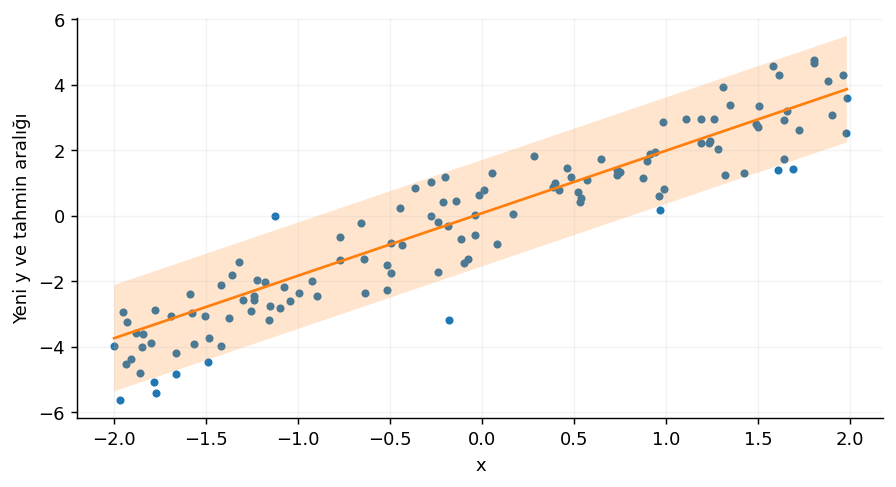

In [96]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

x=rng.uniform(-2,2,(450,1));y=2*x[:,0]+rng.normal(size=450);model=LinearRegression().fit(x[:200],y[:200]);cal=np.abs(y[200:325]-model.predict(x[200:325]));alpha=.1;rank=int(np.ceil((len(cal)+1)*(1-alpha)));q=np.sort(cal)[rank-1];pred=model.predict(x[325:]);covered=np.abs(y[325:]-pred)<=q
print({'kalibrasyon_n':len(cal),'sira':rank,'q':q,'test_kapsama':covered.mean(),'genislik':2*q});order=np.argsort(x[325:,0]);xx=x[325:,0][order];pp=pred[order];plt.scatter(xx,y[325:][order],s=12);plt.plot(xx,pp,c='tab:orange');plt.fill_between(xx,pp-q,pp+q,alpha=.2);plt.xlabel('x');plt.ylabel('Yeni y ve tahmin aralığı')